<a href="https://colab.research.google.com/github/ga642381/ML2021-Spring/blob/main/HW01/HW01.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Homework 1: COVID-19 Cases Prediction (Regression)**

Author: Heng-Jui Chang

Slides: https://github.com/ga642381/ML2021-Spring/blob/main/HW01/HW01.pdf  
Videos (Mandarin): https://cool.ntu.edu.tw/courses/4793/modules/items/172854  
https://cool.ntu.edu.tw/courses/4793/modules/items/172853  
Video (English): https://cool.ntu.edu.tw/courses/4793/modules/items/176529


Objectives:
* Solve a regression problem with deep neural networks (DNN).
* Understand basic DNN training tips.
* Get familiar with PyTorch.

If any questions, please contact the TAs via TA hours, NTU COOL, or email.


# **Download Data**


If the Google drive links are dead, you can download data from [kaggle](https://www.kaggle.com/c/ml2021spring-hw1/data), and upload data manually to the workspace.

In [1]:
tr_path = 'covid.train.csv'  # path to training data
tt_path = 'covid.test.csv'   # path to testing data

#!gdown --id '19CCyCgJrUxtvgZF53vnctJiOJ23T5mqF' --output covid.train.csv
#!gdown --id '1CE240jLm2npU-tdz81-oVKEF3T2yfT1O' --output covid.test.csv

# **Import Some Packages**

In [2]:
# PyTorch
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

# For data preprocess
import numpy as np
import csv
import os

# For plotting
import matplotlib.pyplot as plt
from matplotlib.pyplot import figure

myseed = 42069  # set a random seed for reproducibility
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
np.random.seed(myseed)
torch.manual_seed(myseed)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(myseed)

# **Some Utilities**

You do not need to modify this part.

In [3]:
def get_device():
    ''' Get device (if GPU is available, use GPU) '''
    return 'cuda' if torch.cuda.is_available() else 'cpu'

def plot_learning_curve(loss_record, title=''):
    ''' Plot learning curve of your DNN (train & dev loss) '''
    total_steps = len(loss_record['train'])
    x_1 = range(total_steps)
    x_2 = x_1[::len(loss_record['train']) // len(loss_record['dev'])]
    figure(figsize=(6, 4))
    plt.plot(x_1, loss_record['train'], c='tab:red', label='train')
    plt.plot(x_2, loss_record['dev'], c='tab:cyan', label='dev')
    plt.ylim(0.0, 5.)
    plt.xlabel('Training steps')
    plt.ylabel('MSE loss')
    plt.title('Learning curve of {}'.format(title))
    plt.legend()
    plt.show()


def plot_pred(dv_set, model, device, lim=35., preds=None, targets=None):
    ''' Plot prediction of your DNN '''
    if preds is None or targets is None:
        model.eval()
        preds, targets = [], []
        for x, y in dv_set:
            x, y = x.to(device), y.to(device)
            with torch.no_grad():
                pred = model(x)
                preds.append(pred.detach().cpu())
                targets.append(y.detach().cpu())
        preds = torch.cat(preds, dim=0).numpy()
        targets = torch.cat(targets, dim=0).numpy()

    figure(figsize=(5, 5))
    plt.scatter(targets, preds, c='r', alpha=0.5)
    plt.plot([-0.2, lim], [-0.2, lim], c='b')
    plt.xlim(-0.2, lim)
    plt.ylim(-0.2, lim)
    plt.xlabel('ground truth value')
    plt.ylabel('predicted value')
    plt.title('Ground Truth v.s. Prediction')
    plt.show()

# **Preprocess**

We have three kinds of datasets:
* `train`: for training
* `dev`: for validation
* `test`: for testing (w/o target value)

## **Dataset**

The `COVID19Dataset` below does:
* read `.csv` files
* extract features
* split `covid.train.csv` into train/dev sets
* normalize features

Finishing `TODO` below might make you pass medium baseline.

In [4]:

class COVID19Dataset(Dataset):
    """Dataset for COVID-19 regression."""

    def __init__(self, path, mode='train',
                 target_only=False, norm_stats=None):

        self.mode = mode

        # 1. 读取 CSV，去掉 header 和 id
        with open(path, 'r') as fp:
            data = list(csv.reader(fp))
            data = np.array(data[1:])[:, 1:].astype(float)

        # 2. 特征选择
        if not target_only:
            feats = list(range(93))
        else:
            # 选择的 15 维特征
            feats = [
                40, 41, 42, 43, 57,
                58, 59, 60, 61, 75,
                76, 77, 78, 79, 92
            ]

        # 3. 构造 train / dev / test
        if mode == 'test':
            # Test 没有 target
            self.data = torch.FloatTensor(data[:, feats])

        else:
            # 训练文件的最后一列是 target
            target = data[:, -1]
            data = data[:, feats]

            # 保持原始 Notebook 的划分规则
            if mode == 'train':
                indices = [
                    i for i in range(len(data))
                    if i % 10 != 0
                ]
            elif mode == 'dev':
                indices = [
                    i for i in range(len(data))
                    if i % 10 == 0
                ]
            else:
                raise ValueError(f'Unknown mode: {mode}')

            self.data = torch.FloatTensor(data[indices])
            self.target = torch.FloatTensor(target[indices])

        # 4. 标准化：仅在 Train 上计算统计量
        if mode == 'train':
            self.mean = self.data.mean(
                dim=0, keepdim=True
            )
            self.std = self.data.std(
                dim=0, keepdim=True
            ).clamp_min(1e-8)

        else:
            # Dev / Test 使用 Train 提供的统计量
            if norm_stats is None:
                raise ValueError(
                    'Dev/Test requires training normalization statistics'
                )

            self.mean, self.std = norm_stats

        # 5. 对所有选中的连续特征标准化
        self.data = (
            self.data - self.mean
        ) / self.std

        # 6. 记录输入维数
        self.dim = self.data.shape[1]

        print(
            f'Finished reading {mode}: '
            f'{len(self.data)} samples, '
            f'feature dim = {self.dim}'
        )

    def __getitem__(self, index):
        if self.mode in ['train', 'dev']:
            return self.data[index], self.target[index]
        return self.data[index]

    def __len__(self):
        return len(self.data)


## **DataLoader**

A `DataLoader` loads data from a given `Dataset` into batches.


In [5]:

def prep_dataloader(path, mode, batch_size,n_jobs=0,target_only=False,norm_stats=None):
    dataset = COVID19Dataset(path, mode=mode, target_only=target_only, norm_stats=norm_stats
    )
    dataloader = DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=(mode == 'train'), drop_last=False,
        num_workers=n_jobs, pin_memory=True
    )
    return dataloader


# **Deep Neural Network**

`NeuralNet` is an `nn.Module` designed for regression.
The DNN consists of 2 fully-connected layers with ReLU activation.
This module also included a function `cal_loss` for calculating loss.


In [6]:
class NeuralNet(nn.Module):
    ''' A simple fully-connected deep neural network '''
    def __init__(self, input_dim):
        super(NeuralNet, self).__init__()

        # Define your neural network here
        # TODO: How to modify this model to achieve better performance?
        self.net = nn.Sequential(
            nn.Linear(input_dim, 64),
            nn.ReLU(),
           
            nn.Linear(64, 1)
        )

        # Mean squared error loss
        self.criterion = nn.MSELoss(reduction='mean')

    def forward(self, x):
        ''' Given input of size (batch_size x input_dim), compute output of the network '''
        return self.net(x).squeeze(1)

    def cal_loss(self, pred, target):
        ''' Calculate loss '''
        # TODO: you may implement L1/L2 regularization here
        # mse_loss = self.criterion(pred, target)
        # l2_reg = 0
        # for name, param in self.named_parameters():
        #     if 'weight' in name:
        #         l2_reg += torch.sum(param**2)

        # return mse_loss + 0.5 * 1e-5 * l2_reg
        return self.criterion(pred, target)

# **Train/Dev/Test**

## **Training**

In [7]:
def train(tr_set, dv_set, model, config, device):
    ''' DNN training '''

    n_epochs = config['n_epochs']  # Maximum number of epochs

    # Setup optimizer
    optimizer = getattr(torch.optim, config['optimizer'])(model.parameters(), **config['optim_hparas'])

    min_mse = 1000.
    loss_record = {'train': [], 'dev': []}      # for recording training loss
    early_stop_cnt = 0
    epoch = 0
    while epoch < n_epochs:
        model.train()                           # set model to training mode
        for x, y in tr_set:                     # iterate through the dataloader
            optimizer.zero_grad()               # set gradient to zero
            x, y = x.to(device), y.to(device)   # move data to device (cpu/cuda)
            pred = model(x)                     # forward pass (compute output)
            mse_loss = model.cal_loss(pred, y)  # compute loss
            mse_loss.backward()                 # compute gradient (backpropagation)
            optimizer.step()                    # update model with optimizer
            loss_record['train'].append(mse_loss.detach().cpu().item())

        # After each epoch, test your model on the validation (development) set.
        dev_mse = dev(dv_set, model, device)
        if dev_mse < min_mse:
            # Save model if your model improved
            min_mse = dev_mse
            print('Saving model (epoch = {:4d}, loss = {:.4f})'
                .format(epoch + 1, min_mse))
            torch.save(model.state_dict(), config['save_path'])  # Save model to specified path
            early_stop_cnt = 0
        else:
            early_stop_cnt += 1

        epoch += 1
        loss_record['dev'].append(dev_mse)
        if early_stop_cnt > config['early_stop']:
            # Stop training if your model stops improving for "config['early_stop']" epochs.
            break

    print('Finished training after {} epochs'.format(epoch))
    return min_mse, loss_record

## **Validation**

In [8]:
def dev(dv_set, model, device):
    model.eval()                                # set model to evalutation mode
    total_loss = 0
    for x, y in dv_set:                         # iterate through the dataloader
        x, y = x.to(device), y.to(device)       # move data to device (cpu/cuda)
        with torch.no_grad():                   # disable gradient calculation
            pred = model(x)                     # forward pass (compute output)
            mse_loss = model.cal_loss(pred, y)  # compute loss
        total_loss += mse_loss.detach().cpu().item() * len(x)  # accumulate loss
    total_loss = total_loss / len(dv_set.dataset)              # compute averaged loss

    return total_loss

## **Testing**

In [9]:
def test(tt_set, model, device):
    model.eval()                                # set model to evalutation mode
    preds = []
    for x in tt_set:                            # iterate through the dataloader
        x = x.to(device)                        # move data to device (cpu/cuda)
        with torch.no_grad():                   # disable gradient calculation
            pred = model(x)                     # forward pass (compute output)
            preds.append(pred.detach().cpu())   # collect prediction
    preds = torch.cat(preds, dim=0).numpy()     # concatenate all predictions and convert to a numpy array
    return preds

# **Setup Hyper-parameters**

`config` contains hyper-parameters for training and the path to save your model.

In [10]:
device = get_device()                 # get the current available device ('cpu' or 'cuda')
os.makedirs('models', exist_ok=True)  # The trained model will be saved to ./models/
target_only = True                   # TODO: Using 40 states & 2 tested_positive features

# TODO: How to tune these hyper-parameters to improve your model's performance?
config = {
    'n_epochs': 3000,                # maximum number of epochs
    'batch_size': 64,               # mini-batch size for dataloader
    'optimizer': 'SGD',              # optimization algorithm (optimizer in torch.optim)
    'optim_hparas': {                # hyper-parameters for the optimizer (depends on which optimizer you are using)
        'lr': 0.001,                 # learning rate of SGD
        'momentum': 0.9,              # momentum for SGD
        'weight_decay': 1e-2          # weight decay for L2 regularization
    },
    'early_stop': 200,               # early stopping epochs (the number epochs since your model's last improvement)
    'save_path': 'models/model_15features.pth'  # your model will be saved here
}

# **Load data and model**

In [11]:

# 1. 创建训练集
tr_set = prep_dataloader(
    tr_path,
    'train',
    config['batch_size'],
    target_only=target_only
)

# 2. 获取训练集的标准化参数
norm_stats = (
    tr_set.dataset.mean,
    tr_set.dataset.std
)

# 3. 创建验证集，使用训练集的统计量
dv_set = prep_dataloader(
    tr_path,
    'dev',
    config['batch_size'],
    target_only=target_only,
    norm_stats=norm_stats
)

# 4. 创建测试集，使用相同的统计量
tt_set = prep_dataloader(
    tt_path,
    'test',
    config['batch_size'],
    target_only=target_only,
    norm_stats=norm_stats
)

# 5. 检查维度
assert tr_set.dataset.dim == 15
assert dv_set.dataset.dim == 15
assert tt_set.dataset.dim == 15

print("All datasets have 15 features.")
print("Train shape:", tr_set.dataset.data.shape)
print("Dev shape:", dv_set.dataset.data.shape)
print("Test shape:", tt_set.dataset.data.shape)





Finished reading train: 2430 samples, feature dim = 15
Finished reading dev: 270 samples, feature dim = 15
Finished reading test: 893 samples, feature dim = 15
All datasets have 15 features.
Train shape: torch.Size([2430, 15])
Dev shape: torch.Size([270, 15])
Test shape: torch.Size([893, 15])


In [12]:
model = NeuralNet(tr_set.dataset.dim).to(device)  # Construct model and move to device

# **Start Training!**

In [13]:
model_loss, model_loss_record = train(tr_set, dv_set, model, config, device)

Saving model (epoch =    1, loss = 9.9013)
Saving model (epoch =    2, loss = 1.6675)
Saving model (epoch =    3, loss = 1.2883)
Saving model (epoch =    4, loss = 1.2343)
Saving model (epoch =    6, loss = 1.0953)
Saving model (epoch =    7, loss = 1.0788)
Saving model (epoch =    8, loss = 1.0616)
Saving model (epoch =   10, loss = 0.9802)
Saving model (epoch =   17, loss = 0.8929)
Saving model (epoch =   22, loss = 0.8792)
Saving model (epoch =   25, loss = 0.8590)
Saving model (epoch =   28, loss = 0.8586)
Saving model (epoch =   29, loss = 0.8497)
Saving model (epoch =   31, loss = 0.8486)
Saving model (epoch =   33, loss = 0.8467)
Saving model (epoch =   34, loss = 0.8438)
Saving model (epoch =   36, loss = 0.8391)
Saving model (epoch =   39, loss = 0.8326)
Saving model (epoch =   41, loss = 0.8321)
Saving model (epoch =   42, loss = 0.8304)
Saving model (epoch =   49, loss = 0.8252)
Saving model (epoch =   51, loss = 0.8247)
Saving model (epoch =   60, loss = 0.8206)
Saving mode

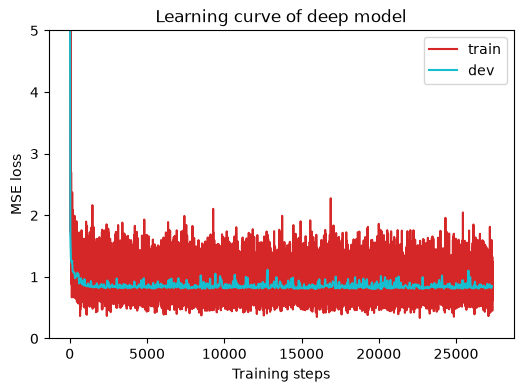

In [14]:
plot_learning_curve(model_loss_record, title='deep model')

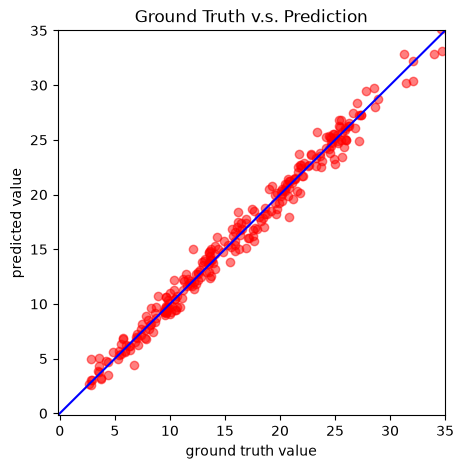

In [15]:
del model
model = NeuralNet(tr_set.dataset.dim).to(device)
ckpt = torch.load(config['save_path'], map_location='cpu')  # Load your best model
model.load_state_dict(ckpt)
plot_pred(dv_set, model, device)  # Show prediction on the validation set

# **Testing**
The predictions of your model on testing set will be stored at `pred.csv`.

In [16]:
def save_pred(preds, file):
    ''' Save predictions to specified file '''
    print('Saving results to {}'.format(file))
    with open(file, 'w') as fp:
        writer = csv.writer(fp)
        writer.writerow(['id', 'tested_positive'])
        for i, p in enumerate(preds):
            writer.writerow([i, p])

preds = test(tt_set, model, device)  # predict COVID-19 cases with your model
save_pred(preds, 'pred_15features.csv')         # save prediction file to pred.csv

Saving results to pred_15features.csv


# **Hints**

## **Simple Baseline**
* Run sample code

## **Medium Baseline**
* Feature selection: 40 states + 2 `tested_positive` (`TODO` in dataset)

## **Strong Baseline**
* Feature selection (what other features are useful?)
* DNN architecture (layers? dimension? activation function?)
* Training (mini-batch? optimizer? learning rate?)
* L2 regularization
* There are some mistakes in the sample code, can you find them?

# **Reference**
This code is completely written by Heng-Jui Chang @ NTUEE.  
Copying or reusing this code is required to specify the original author. 

E.g.  
Source: Heng-Jui Chang @ NTUEE (https://github.com/ga642381/ML2021-Spring/blob/main/HW01/HW01.ipynb)
